In [110]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns

In [111]:
df = pd.read_csv('./datasets/penguins.csv')
df.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


<img src="images/peng.jpg" width="400">


# Palmer Penguins: Data Dictionary


## Columns

| Column | Alt. name (raw/Kaggle) | Type | Description |
|---|---|---|---|
| `species` | `Species` | Categorical | Penguin species: Adelie, Chinstrap, or Gentoo |
| `island` | `Island` | Categorical | Island of observation: Biscoe, Dream, or Torgersen |
| `bill_length_mm` | `culmen_length_mm` | Float | Length of the bill (beak) along the top ridge, in millimeters |
| `bill_depth_mm` | `culmen_depth_mm` | Float | Depth of the bill from the top ridge to the bottom edge, in millimeters |
| `flipper_length_mm` | `flipper_length_mm` | Float/Int | Length of the flipper (wing), in millimeters |
| `body_mass_g` | `body_mass_g` | Float/Int | Body weight, in grams |
| `sex` | `Sex` | Categorical | Male or Female |
| `year` | `year` | Integer | Year of the observation: 2007, 2008, or 2009 (not in every version) |

In [112]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
 7   year               344 non-null    int64  
dtypes: float64(4), int64(1), object(3)
memory usage: 21.6+ KB


### `Changing Dtype of bill_length_mm to save memory`

In [113]:
print(df["bill_length_mm"].memory_usage(index=False))   
df["bill_length_mm"] = df["bill_length_mm"].astype("float32")
print(df["bill_length_mm"].memory_usage(index=False))   

2752
1376


### `How do we fill sex feature? 1. mode 2. unknown`

In [114]:
df['sex'].isna().sum()

np.int64(11)

In [115]:
df['sex'] = df['sex'].fillna('Unknown')
df['sex'].value_counts()

sex
male       168
female     165
Unknown     11
Name: count, dtype: int64

`How much is missing.`

Under about 5%: almost any method is fine, and dropping rows is often acceptable. </br>
5-30%: be careful, and test whether your conclusions change with a different method.</br>
Above that: filling with a constant can distort results badly, and the column may not be trustworthy.

### `Examine correlation of numerical features`

In [116]:
numericals = df.select_dtypes(include="number")
print(numericals)

     bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g  year
0         39.099998           18.7              181.0       3750.0  2007
1         39.500000           17.4              186.0       3800.0  2007
2         40.299999           18.0              195.0       3250.0  2007
3               NaN            NaN                NaN          NaN  2007
4         36.700001           19.3              193.0       3450.0  2007
..              ...            ...                ...          ...   ...
339       55.799999           19.8              207.0       4000.0  2009
340       43.500000           18.1              202.0       3400.0  2009
341       49.599998           18.2              193.0       3775.0  2009
342       50.799999           19.0              210.0       4100.0  2009
343       50.200001           18.7              198.0       3775.0  2009

[344 rows x 5 columns]


### `Which features are better candidates to be dropped?`

#### `Variance Check`

1. If every row has nearly the same value, the feature can’t explain differences in the target.</br>
2. It adds noise and cost, and in some models (linear regression, PCA) near-constant columns cause numerical problems.</br>
3. A column with a single value (variance exactly 0) is always safe to remove.

In [117]:
numericals.var()

bill_length_mm           29.807041
bill_depth_mm             3.899808
flipper_length_mm       197.731792
body_mass_g          643131.077327
year                      0.669706
dtype: float64

### `Correlation Check`

1. If two features measure nearly the same thing

In [118]:
numericals.corr()

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,year
bill_length_mm,1.000000,-0.235053,0.656181,0.595110,0.054545
bill_depth_mm,-0.235053,1.000000,-0.583851,-0.471916,-0.060354
flipper_length_mm,0.656181,-0.583851,1.000000,0.871202,0.169675
body_mass_g,0.595110,-0.471916,0.871202,1.000000,0.042209
year,0.054545,-0.060354,0.169675,0.042209,1.000000


## `A decision is made - remove the year feature`

In [119]:
df.drop(columns=['year'])

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.099998,18.7,181.0,3750.0,male
1,Adelie,Torgersen,39.500000,17.4,186.0,3800.0,female
2,Adelie,Torgersen,40.299999,18.0,195.0,3250.0,female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,Unknown
4,Adelie,Torgersen,36.700001,19.3,193.0,3450.0,female
...,...,...,...,...,...,...,...
339,Chinstrap,Dream,55.799999,19.8,207.0,4000.0,male
340,Chinstrap,Dream,43.500000,18.1,202.0,3400.0,female
341,Chinstrap,Dream,49.599998,18.2,193.0,3775.0,male
342,Chinstrap,Dream,50.799999,19.0,210.0,4100.0,male


### `fill these features with median`

In [120]:
cols = ["bill_depth_mm", "bill_length_mm", 'body_mass_g','flipper_length_mm']

df[cols] = df[cols].fillna(df[cols].median())

In [121]:
df[['bill_depth_mm', 'bill_length_mm']].isna().sum()

bill_depth_mm     0
bill_length_mm    0
dtype: int64

<img src="images/temp.jpg" width="300">

## `temporal leakage`

Suppose you want a model that will predict tomorrow from today. If you train it on data from 2024 and test it on 2022, the model has already seen what happened after those dates, so it can pick up patterns the real world never gives you in advance. Your evaluation is too optimistic.

## `Check for Duplication`

In [122]:
df.duplicated().value_counts()

False    344
Name: count, dtype: int64

In [123]:
g = df.groupby("species")
g.size()

species
Adelie       152
Chinstrap     68
Gentoo       124
dtype: int64

In [124]:
measurements = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
g[measurements].agg(["mean", "median", "std"]).round(1)

bill_length_mm                 bill_depth_mm              \
                    mean     median  std          mean median  std   
species                                                              
Adelie         38.799999  38.799999  2.7          18.3   18.4  1.2   
Chinstrap      48.799999  49.599998  3.3          18.4   18.4  1.1   
Gentoo         47.500000  47.200001  3.1          15.0   15.0  1.0   

          flipper_length_mm             body_mass_g                 
                       mean median  std        mean  median    std  
species                                                             
Adelie                190.0  190.0  6.5      3703.0  3700.0  457.9  
Chinstrap             195.8  196.0  7.1      3733.1  3700.0  384.3  
Gentoo                217.0  216.0  6.7      5067.7  5000.0  510.4

In [125]:
g[measurements].apply(lambda d: d.isna().sum())


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
species,,,,
Adelie,0,0,0,0
Chinstrap,0,0,0,0
Gentoo,0,0,0,0


In [126]:
g["sex"].apply(lambda s: s.isna().sum())

species
Adelie       0
Chinstrap    0
Gentoo       0
Name: sex, dtype: int64

<Axes: xlabel='species', ylabel='count'>

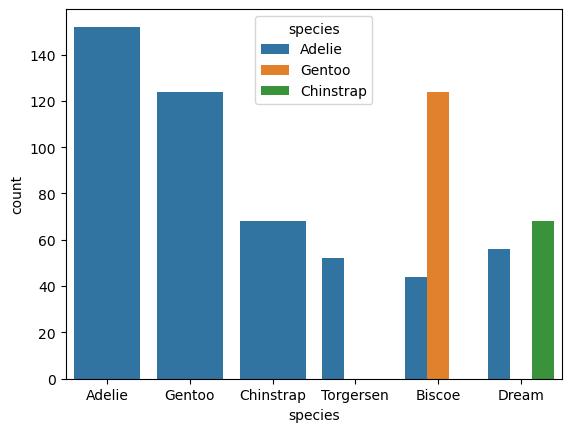

In [131]:
sns.countplot(data=df, x="species")
sns.countplot(data=df, x="island", hue="species")   # species within each island

<Axes: xlabel='species', ylabel='body_mass_g'>

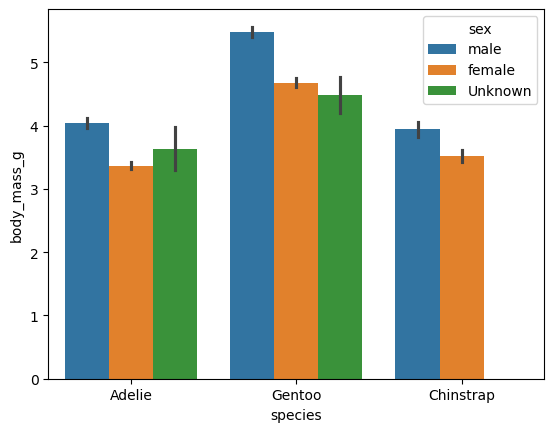

In [139]:
sns.barplot(data=df, x="species", y="body_mass_g", hue="sex")

Gentoo is the heaviest species, and males outweigh females within every species.

<Axes: xlabel='flipper_length_mm', ylabel='body_mass_g'>

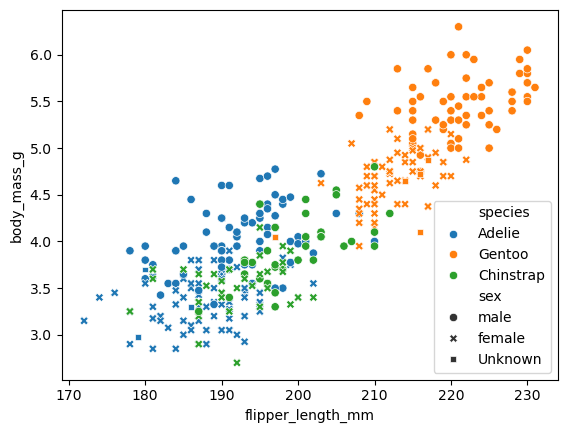

In [136]:
sns.scatterplot(data=df, x="flipper_length_mm", y="body_mass_g", hue="species", style="sex")

Gentoo is clearly different: mean body mass about 5,076 g, against about 3,700 g for Adelie and Chinstrap, and a shallower bill (about 15.0 mm against about 18.3 mm). </br>
Adelie vs Chinstrap are similar in mass (3,701 g vs 3,733 g) but differ in bill length (38.8 vs 48.8 mm). So no single feature separates all three, and that is a useful modeling lesson.</br>
Mean vs median: if they differ a lot inside a group, the distribution is skewed or has outliers.</br>
Spread: compare the standard deviations, or the coefficient of variation (std / mean). Here they’re similar (about 10 to 12% for body mass).

# `Transform from G to KG`

In [127]:
df['body_mass_g'] = df['body_mass_g'] / 1000


In [ ]:
df.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.099998,18.7,181.0,3.75,male,2007
1,Adelie,Torgersen,39.500000,17.4,186.0,3.80,female,2007
2,Adelie,Torgersen,40.299999,18.0,195.0,3.25,female,2007
3,Adelie,Torgersen,44.450001,17.3,197.0,4.05,Unknown,2007
4,Adelie,Torgersen,36.700001,19.3,193.0,3.45,female,2007


In [130]:
for i in df.columns:
    print(i, df[i].isna().sum())

species 0
island 0
bill_length_mm 0
bill_depth_mm 0
flipper_length_mm 0
body_mass_g 0
sex 0
year 0
